# Atera 空间可视化 — 整体图、6 个圆形 ROI 与物理比例尺

本 notebook 用一份**原始 Atera 乳腺癌数据**（WTA Breast Cancer FFPE、DCIS）走完一条出图链路：

1. **读取**：从 Atera 原始输出目录直接读，包括它自己的 `cell_groups.csv` 聚类
2. **整体图**：`total_counts` 与 `cell_group` 两个**点图**左右并列（squidpy），不用细胞轮廓
3. **选 6 个 ROI**：2 行 × 3 列、整齐对齐在切片上，每个 ROI 是一个「圆心 + 物理半径」的圆
4. **拆开**：6 个 ROI 各自的 spatial cluster 放左边，被抠剩的组织放右边
5. **距离场**：6 个 ROI 分别按「到各自圆心的物理距离（µm）」着色
6. **缩小半径**：同一个圆心、半径缩到 100 µm，改画**细胞轮廓**——cluster 版与基因表达版

每张图都带**物理比例尺**，长度随视野自动变化：整体图 1000 µm、ROI 图 100 µm、细胞级 50 µm。

需要 `trackcell >= 0.4.5`，以及 `squidpy`（点图用）与 `scanpy`。

数据目录用环境变量 `ATERA_DATA` 指定，指向包含 `breast_preview/` 的那个 run 目录。

In [1]:
import os
import time
import warnings
from pathlib import Path

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message="No data for colormapping.*")
warnings.filterwarnings("ignore", message="Trying to modify attribute.*")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, Normalize
from matplotlib.cm import ScalarMappable
from matplotlib.patches import Patch

import trackcell as tcl
import squidpy as sq

DATA_DIR = Path(os.environ.get("ATERA_DATA", ".")).expanduser()
ROI_DIR = DATA_DIR / "breast_preview"      # 一个 ROI bundle = Atera 的一次输出

plt.rcParams["figure.dpi"] = 100
print("trackcell :", tcl.__version__)
print("bundle    :", ROI_DIR.name, "| exists:", ROI_DIR.exists())

trackcell : 0.4.6
bundle    : breast_preview | exists: True


## 1. 从原始 Atera 数据读取

`tcl.io.read_atera()` 自动识别格式。preview 数据是 Xenium-v4 兼容的
`cell_feature_matrix.h5` + `cells.parquet` + `cell_boundaries.parquet`，
官方数据是 AnnData Zarr + `cells.zarr`，两种读出来结构一致。

`cell_groups.csv` 是 Atera 自己给出的单细胞聚类（这里是 19 个群，含 11q13 扩增的
DCIS 亚群），会被读成 `obs['cell_group']`，配色放在
`uns['cell_group_colors']` —— 所以下面所有图用的都是厂商原始分类，不是我又重新聚的。

读 17 万细胞 + 多边形大约 1 分钟。

In [2]:
t0 = time.time()
adata = tcl.io.read_atera(
    ROI_DIR,
    sample="breast",
    build_polygons=True,        # 最后一步要画细胞轮廓
    include_nucleus=False,      # 不用核多边形，省一半构建时间
    verbose=False,
)
print(f"read {adata.n_obs:,} cells × {adata.n_vars:,} genes in {time.time() - t0:.0f}s")

mpp, unit = tcl.pl.resolve_microns_per_unit(adata, library_id="breast")
coords = np.asarray(adata.obsm["spatial"])
span = np.ptp(coords, axis=0)
print(f"microns per data unit : {mpp} ({unit})")
print(f"切片范围              : {span[0]:.0f} × {span[1]:.0f} µm")
print(f"cell_group            : {adata.obs['cell_group'].nunique()} 群, "
      f"未分配 {int(adata.obs['cell_group'].isna().sum())} 个细胞")

read 170,057 cells × 27,104 genes in 43s
microns per data unit : 1.0 (um)
切片范围              : 9879 × 5940 µm
cell_group            : 19 群, 未分配 12 个细胞


19 个群的配色直接取自 `uns['cell_group_colors']`，拼成一个 `ListedColormap`，
顺序与 `obs['cell_group'].cat.categories` 一致 —— 这样每张图里的同一种颜色永远指同一个群。

In [3]:
CATS = list(adata.obs["cell_group"].cat.categories)
COLORS = adata.uns["cell_group_colors"]
CLUSTER_CMAP = ListedColormap([COLORS[c] for c in CATS])

adata.obs["log1p_total_counts"] = np.log1p(adata.obs["total_counts"].astype(float))
adata.obs[["total_counts", "log1p_total_counts"]].describe().loc[["mean", "50%", "max"]].round(2)

,total_counts,log1p_total_counts
mean,2950.37,7.59
50%,2118.00,7.66
max,26103.00,10.17


## 2. 整体 spatial 图：`total_counts` 与 cluster 左右并列

整体图用**点图**（squidpy `spatial_scatter`）就够了：17 万个细胞画轮廓既慢又糊。
左panel 是测序深度，右panel 是 Atera 自己的聚类。

比例尺由 `tcl.pl.add_scale_bar()` 画 —— 它接受任何 matplotlib 坐标轴，所以
squidpy 的图也能加。切片 9.9 mm 宽，自动比例尺给 1000 µm。

scale bar: 1000 µm  (9.2% of the width)
scale bar: 1000 µm  (9.2% of the width)


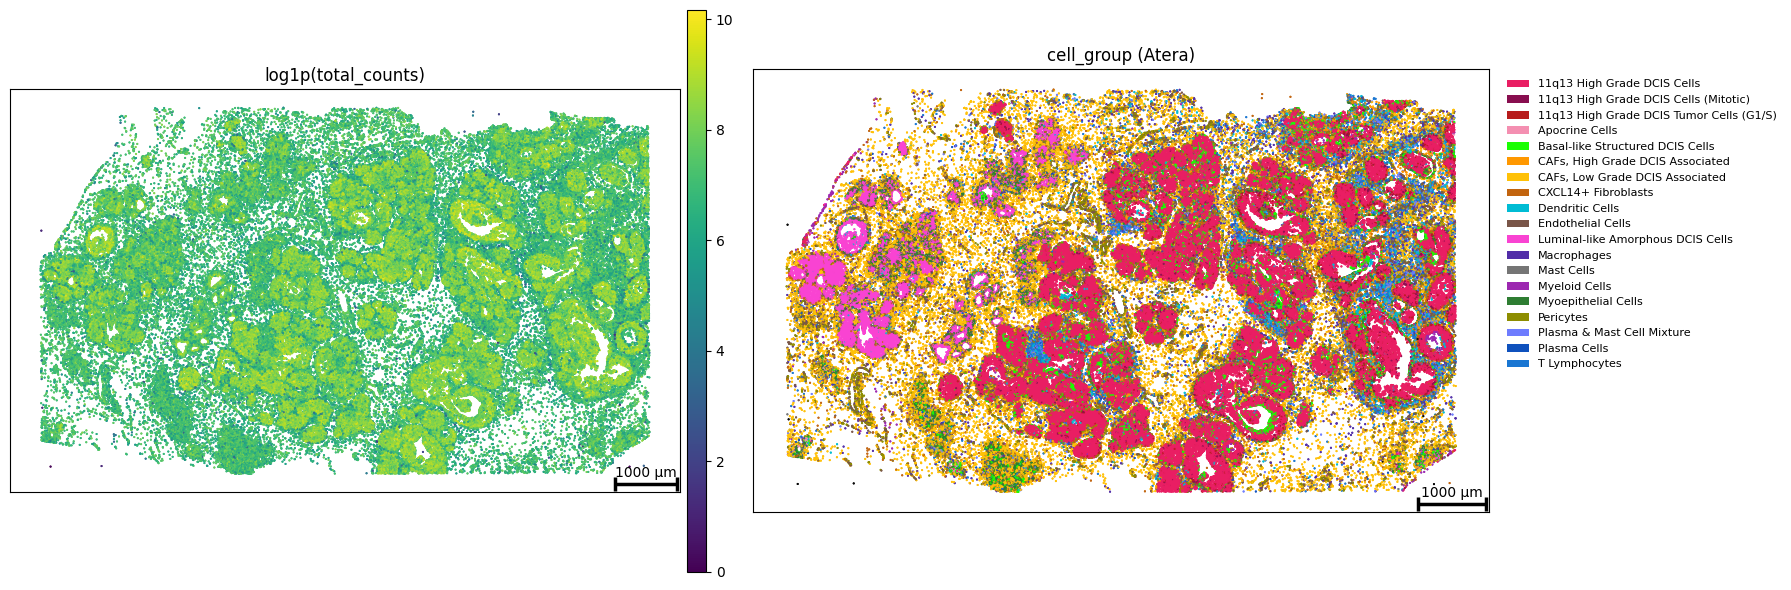

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

sq.pl.spatial_scatter(
    adata, library_id="breast", color="log1p_total_counts", shape=None, size=2,
    ax=axes[0], legend_loc=None, title="",
)
axes[0].set_title("log1p(total_counts)")

sq.pl.spatial_scatter(
    adata, library_id="breast", color="cell_group", shape=None, size=2,
    palette=CLUSTER_CMAP, ax=axes[1], legend_loc=None, title="",
)
axes[1].set_title("cell_group (Atera)")

for ax in axes:
    ax.set_aspect("equal")
    ax.set_xlabel(""); ax.set_ylabel("")
    info = tcl.pl.add_scale_bar(ax, adata, library_id="breast", loc="lower right")
    print(f"scale bar: {info['label']}  ({info['axes_fraction']:.1%} of the width)")

handles = [Patch(facecolor=CLUSTER_CMAP(i / len(CATS)), edgecolor="none", label=c)
           for i, c in enumerate(CATS)]
axes[1].legend(handles=handles, bbox_to_anchor=(1.01, 1), loc="upper left",
               frameon=False, fontsize=8)
fig.tight_layout()
plt.show()

## 3. 选 6 个 ROI：2 行 × 3 列，整齐对齐

ROI 用「圆心 + 物理半径」定义，不用手绘多边形：可以写进方法学段落，也可以在别的样本上
原样重跑。这里把圆心放在切片外接框的固定分数位置上（x 取 20%/50%/80%，y 取 32%/68%），
所以 6 个圆在图上排成规整的两行三列。

做法是把切片外接框切成 **2 行 × 3 列** 六个格子，每个圆心的位置取该格子里细胞坐标的
**中位数** —— 这样 6 个圆既保持规整的两行三列，又不会落在没有组织的空白处
（直接取格子几何中心时，左下角那个格子会空到只剩几十个细胞）。

半径取 300 µm：在 9.9 mm × 5.9 mm 的切片上互不重叠，每个 ROI 里有几百到一千多个细胞。

In [5]:
RADIUS = 300.0     # µm，ROI 半径
x_lo, y_lo = coords.min(axis=0)
x_hi, y_hi = coords.max(axis=0)

# 2 行 × 3 列六个格子，每个格子取细胞坐标中位数当圆心
x_edges = np.linspace(x_lo, x_hi, 4)
y_edges = np.linspace(y_lo, y_hi, 3)
centers = []
for row in range(2):
    for col in range(3):
        in_cell = (
            (coords[:, 0] >= x_edges[col]) & (coords[:, 0] < x_edges[col + 1])
            & (coords[:, 1] >= y_edges[row]) & (coords[:, 1] < y_edges[row + 1])
        )
        centers.append(tuple(float(v) for v in np.median(coords[in_cell], axis=0)))

roi_masks = [tcl.tl.cells_in_radius(adata, c, RADIUS) for c in centers]
inside = np.zeros(adata.n_obs, dtype=bool)
for m in roi_masks:
    inside |= m

summary = pd.DataFrame({
    "roi": [f"ROI{i}" for i in range(1, 7)],
    "center_x_um": [round(c[0]) for c in centers],
    "center_y_um": [round(c[1]) for c in centers],
    "cells": [int(m.sum()) for m in roi_masks],
})
print(f"6 个 ROI 合计 {int(inside.sum()):,} 细胞；剩余组织 {int((~inside).sum()):,} 细胞")
summary

6 个 ROI 合计 7,309 细胞；剩余组织 162,748 细胞


,roi,center_x_um,center_y_um,cells
0,ROI1,1765,2200,1360
1,ROI2,5116,1762,1200
2,ROI3,8291,1723,1533
3,ROI4,2095,4158,711
4,ROI5,4604,4436,1458
5,ROI6,8182,3999,1047


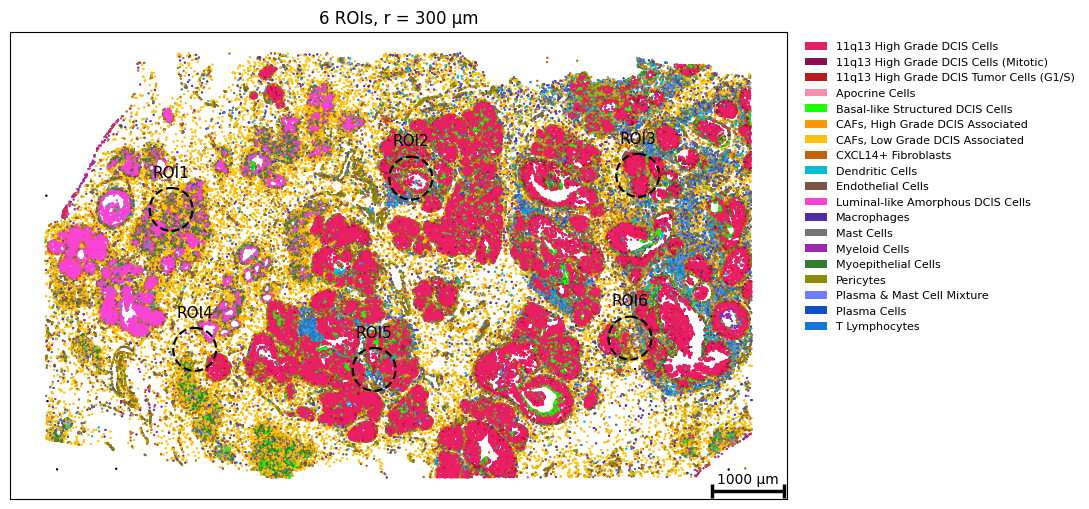

In [6]:
fig, ax = plt.subplots(figsize=(11, 7))
sq.pl.spatial_scatter(adata, library_id="breast", color="cell_group", shape=None,
                      size=2, palette=CLUSTER_CMAP, ax=ax, legend_loc=None, title="")

for i, c in enumerate(centers, start=1):
    tcl.pl.mark_circle(ax, c, RADIUS, radius_unit="um", adata=adata,
                       edges_color="black", edges_width=1.6, linestyle="--", show=False)
    ax.text(c[0], c[1] - RADIUS - 110, f"ROI{i}", ha="center", va="bottom",
            fontsize=11, color="black", zorder=110)

ax.set_aspect("equal")
ax.set_xlabel(""); ax.set_ylabel("")
ax.set_title(f"6 ROIs, r = {RADIUS:.0f} µm", fontsize=12)
tcl.pl.add_scale_bar(ax, adata, library_id="breast", loc="lower right")

handles = [Patch(facecolor=CLUSTER_CMAP(i / len(CATS)), edgecolor="none", label=c)
           for i, c in enumerate(CATS)]
ax.legend(handles=handles, bbox_to_anchor=(1.01, 1), loc="upper left",
          frameon=False, fontsize=8)
fig.tight_layout()
plt.show()

## 4. 拆开：6 个 ROI 在左，被抠剩的组织在右

左边 2 × 3 是 6 个 ROI 的 spatial cluster 图，每个 panel 用**相同的视野宽度**
（2 × 半径 × 1.06），所以它们之间可以直接比较；右边是被抠走这 6 个圆之后
剩下的组织 —— 圆形的空洞正好是这 6 个 ROI 的位置。

每个 panel 的比例尺都是 100 µm，和 300 µm 的 ROI 直径对得上，读者能直接估尺度。

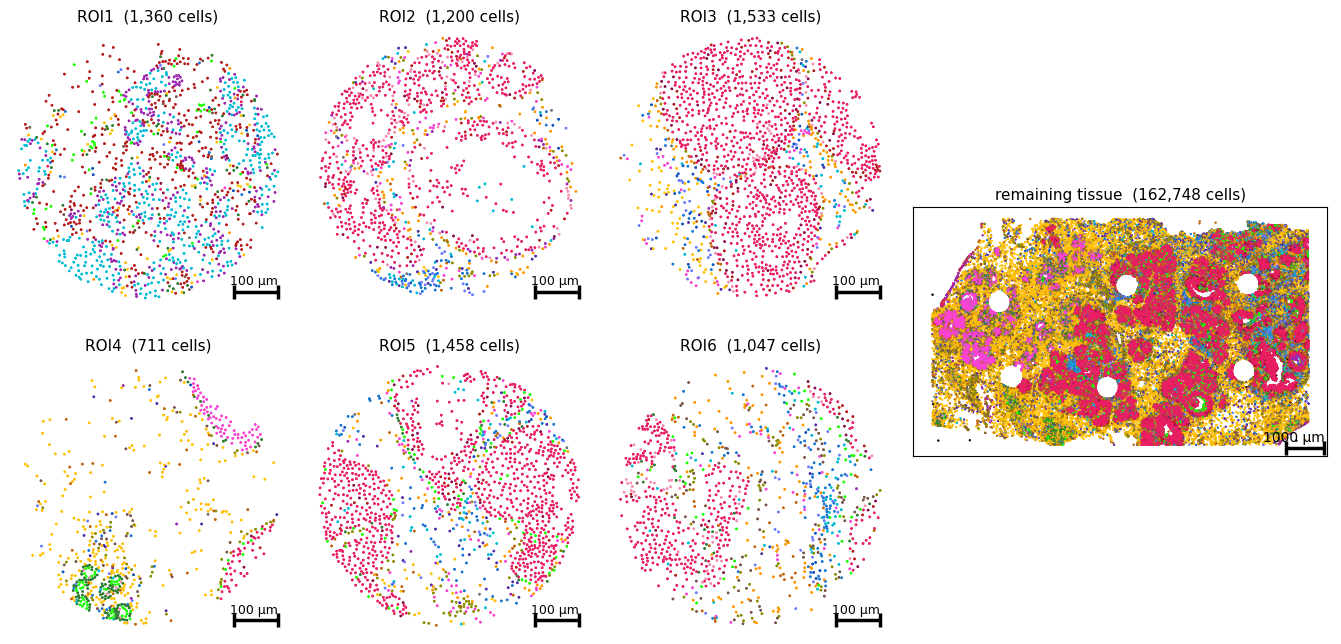

In [7]:
def style_roi_axis(ax, center, radius, pad=1.06):
    # Same window for every ROI panel, so the panels stay comparable.
    ax.set_xlim(center[0] - radius * pad, center[0] + radius * pad)
    ax.set_ylim(center[1] + radius * pad, center[1] - radius * pad)
    ax.set_aspect("equal")
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_xlabel(""); ax.set_ylabel("")
    for side in ax.spines.values():
        side.set_visible(False)


fig = plt.figure(figsize=(17, 8))
gs = fig.add_gridspec(2, 4, width_ratios=[1, 1, 1, 1.5], wspace=0.08, hspace=0.14)

for i, (center, mask) in enumerate(zip(centers, roi_masks)):
    ax = fig.add_subplot(gs[i // 3, i % 3])
    sq.pl.spatial_scatter(adata[mask].copy(), library_id="breast", color="cell_group",
                          shape=None, size=6, palette=CLUSTER_CMAP, ax=ax,
                          legend_loc=None, title="")
    style_roi_axis(ax, center, RADIUS)
    ax.set_title(f"ROI{i + 1}  ({int(mask.sum()):,} cells)", fontsize=11)
    tcl.pl.add_scale_bar(ax, adata, library_id="breast", length="100um",
                         loc="lower right", linewidth=2.5, fontsize=9, frame=True)

ax = fig.add_subplot(gs[:, 3])
sq.pl.spatial_scatter(adata[~inside].copy(), library_id="breast", color="cell_group",
                      shape=None, size=2, palette=CLUSTER_CMAP, ax=ax,
                      legend_loc=None, title="")
ax.set_aspect("equal")
ax.set_xticks([]); ax.set_yticks([])
ax.set_xlabel(""); ax.set_ylabel("")
ax.set_title(f"remaining tissue  ({int((~inside).sum()):,} cells)", fontsize=11)
tcl.pl.add_scale_bar(ax, adata, library_id="breast", loc="lower right")

plt.show()

## 5. 6 个 ROI 的「到圆心物理距离」场

`tcl.tl.cells_in_radius(..., return_distances=True)` 直接给出每个细胞到圆心的
**物理距离（µm）**，不需要自己算 Euclid —— 像素坐标的数据会自动乘
`microns_per_pixel`，Atera 的坐标本身已是 µm，因子为 1.0。

颜色用 `viridis`（也可以用任何 matplotlib colormap）。6 个 panel 共用同一个
0–300 µm 的色标，所以面板之间可以直接比较：DCIS 导管中心离圆心近、间质离得远。

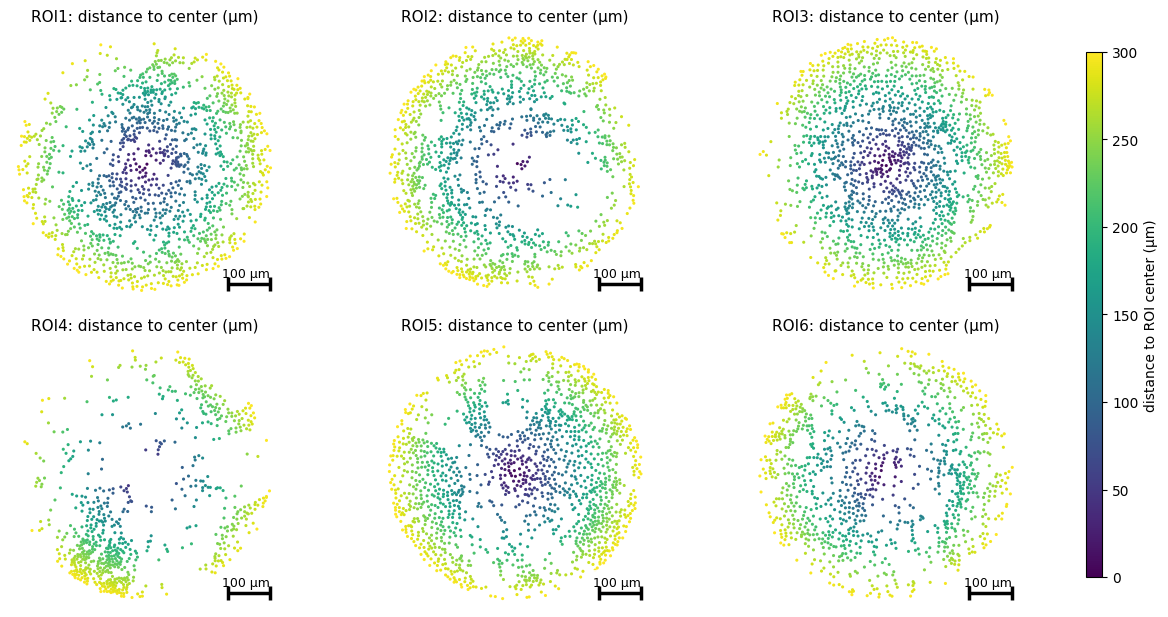

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7.5))
norm = Normalize(0, RADIUS)

for i, (center, mask) in enumerate(zip(centers, roi_masks)):
    ax = axes[i // 3, i % 3]
    _, dist_um = tcl.tl.cells_in_radius(
        adata, center, RADIUS, return_distances=True
    )
    xy = np.asarray(adata[mask].obsm["spatial"])
    ax.scatter(xy[:, 0], xy[:, 1], c=dist_um[mask], cmap="viridis",
               norm=norm, s=5, linewidths=0)
    style_roi_axis(ax, center, RADIUS)
    ax.set_title(f"ROI{i + 1}: distance to center (µm)", fontsize=11)
    tcl.pl.add_scale_bar(ax, adata, library_id="breast", length="100um",
                         loc="lower right", linewidth=2.5, fontsize=9, frame=True)

fig.subplots_adjust(right=0.9, hspace=0.15, wspace=0.08)
cax = fig.add_axes([0.92, 0.15, 0.012, 0.7])
fig.colorbar(ScalarMappable(norm=norm, cmap="viridis"), cax=cax,
             label="distance to ROI center (µm)")
plt.show()

## 6. 缩小半径：改画细胞轮廓

同 6 个圆心，半径从 300 µm 缩到 100 µm（每个 ROI 几十到两百多个细胞），
这时轮廓图才有意义 —— `tcl.pl.spatial_cell()` 直接用 `cells.zarr` /
`cell_boundaries.parquet` 里的多边形，不是圆点。

先看 cluster：颜色仍是 Atera 那 19 个群、那套配色。

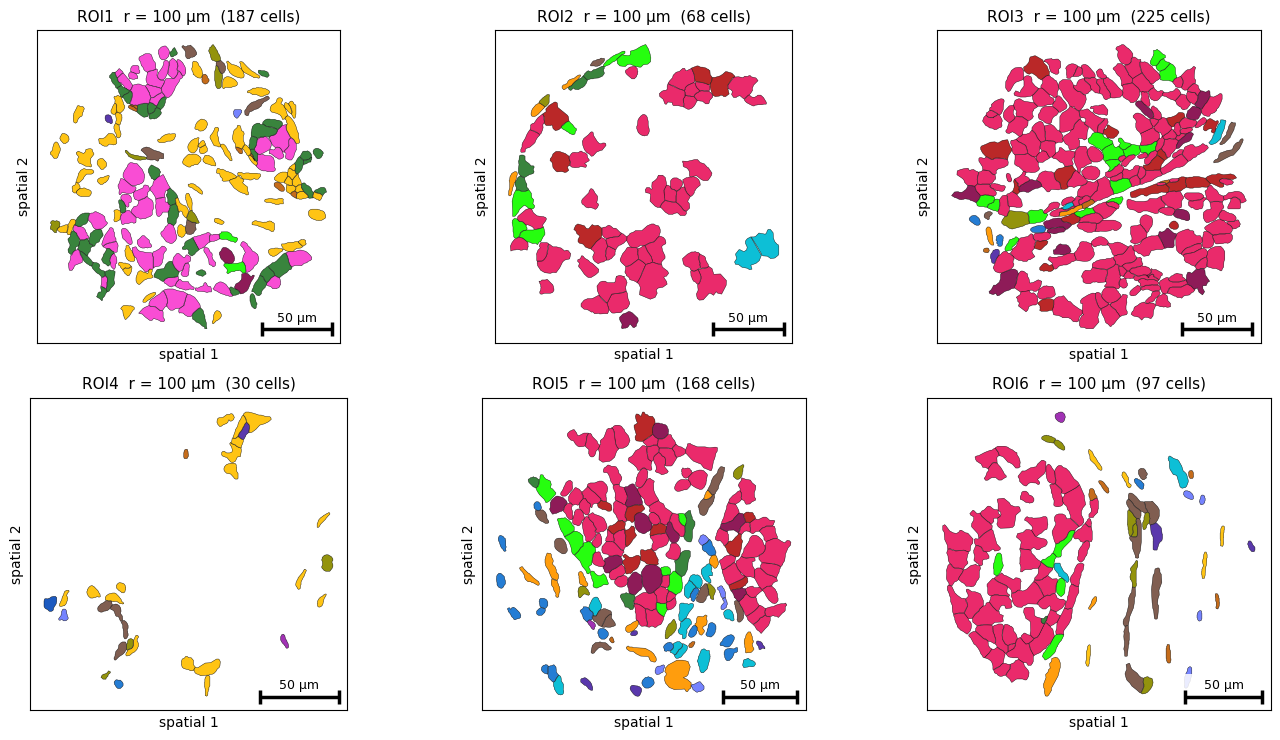

In [9]:
ZOOM = 100.0       # µm，缩小后的半径

fig, axes = plt.subplots(2, 3, figsize=(14, 7.5))
for i, center in enumerate(centers):
    ax = axes[i // 3, i % 3]
    mask = tcl.tl.cells_in_radius(adata, center, ZOOM)
    tcl.pl.spatial_cell(
        adata[mask].copy(), color="cell_group", palette=COLORS,
        edges_width=0.3, alpha=0.95, legend=False, show=False, ax=ax,
        scalebar=dict(length="50um", loc="lower right", linewidth=2.5,
                      fontsize=9, frame=True),
    )
    ax.set_title(f"ROI{i + 1}  r = {ZOOM:.0f} µm  ({int(mask.sum())} cells)",
                 fontsize=11)
fig.tight_layout()
plt.show()

同一批细胞，换成基因表达。这里画 `CCND1` —— 它就在 Atera `gene_groups.csv` 里标出的
11q13 扩增子内，是这个 DCIS 病例里表达最高的扩增基因，正好能看出哪些导管上皮带着扩增。

（`gene_groups.csv` 里的基因清单可以用 `pd.read_csv(ROI_DIR / "gene_groups.csv")` 自查。）

11q13 扩增子平均表达最高的基因: CCND1


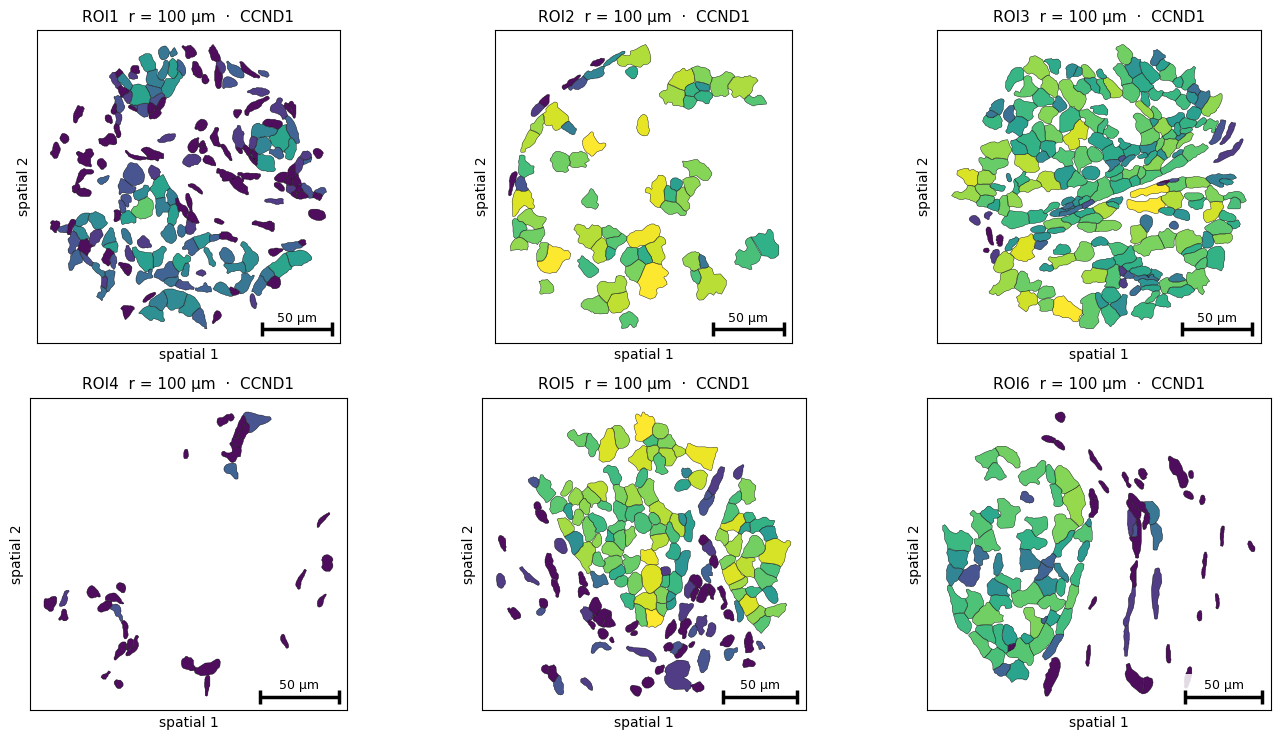

In [10]:
amplicon = pd.read_csv(ROI_DIR / "gene_groups.csv").query("group == '11q13 Amplicon Genes'")
amplicon = [g for g in amplicon["gene"] if g in adata.var_names]
means = {g: float(adata[:, g].X.mean()) for g in amplicon}
GENE = max(means, key=means.get)
print("11q13 扩增子平均表达最高的基因:", GENE)

# 稀疏矩阵直接取一列并落成 obs 列，画图时按列名引用
vec = adata[:, GENE].X
vec = vec.toarray().ravel() if hasattr(vec, "toarray") else np.asarray(vec).ravel()
adata.obs[f"{GENE}_log1p"] = np.log1p(vec)
GENE_COL = f"{GENE}_log1p"
p99 = float(np.percentile(adata.obs[GENE_COL], 99))

fig, axes = plt.subplots(2, 3, figsize=(14, 7.5))
for i, center in enumerate(centers):
    ax = axes[i // 3, i % 3]
    mask = tcl.tl.cells_in_radius(adata, center, ZOOM)
    tcl.pl.spatial_cell(
        adata[mask].copy(), color=GENE_COL, cmap="viridis", vmin=0.0, vmax=p99,
        edges_width=0.3, alpha=0.95, legend=False, show=False, ax=ax,
        scalebar=dict(length="50um", loc="lower right", linewidth=2.5,
                      fontsize=9, frame=True),
    )
    ax.set_title(f"ROI{i + 1}  r = {ZOOM:.0f} µm  ·  {GENE}", fontsize=11)
fig.tight_layout()
plt.show()

## 7. 比例尺速查

| 参数 | 说明 |
|---|---|
| `scalebar=True` | 自动长度：可见宽度的 ~18%，取 1/2/5×10ⁿ µm |
| `scalebar="50um"` | 定长（也接受 `100 µm`、`20px`） |
| `loc` | `lower right` / `upper left` / `center right` … |
| `offset` / `pad` | 额外位移（点）/ 轴内缩（轴分数） |
| `linewidth` / `fontsize` / `color` / `alpha` | 线宽、字号、颜色、透明度 |
| `caps` / `cap_size` | 端点短竖线 |
| `label` / `label_position` | 文字内容 / `auto`、`above`、`below`、`none` |
| `frame` | H&E 背景上的衬底框 |
| `microns_per_unit` | 覆盖单位推断（无 scalefactors 的像素坐标） |

比例尺在被裁剪进框内：连端点、文字、衬底框一起算，**而且**在
`tight_layout()` / `savefig(bbox_inches="tight")` / 窗口缩放之后重新摆位，
所以不会压到 axes 边框上，也不会被裁掉。

`tcl.pl.add_scale_bar()` 也能单独用在任何 matplotlib 轴上（本页的 squidpy 点图就是这样加的）：

```python
info = tcl.pl.add_scale_bar(ax, adata, length="1000um", loc="lower right")
# {'length': 1000.0, 'label': '1000 µm', 'axes_fraction': 0.10, ...}
```

## 小结

* Atera 原始输出直接读：矩阵 + 多边形 + 厂商自己的 `cell_groups.csv` 聚类
* 整体图用点图就够（`total_counts` / `cluster` 并列），ROI 与细胞级才上轮廓
* ROI 用「圆心 + 物理半径」定义：`tl.cells_in_radius()`，可复现、可报告、可换样本重跑
* 6 个 ROI 排成 2 × 3，既能整体对照看，也能单独放大看
* 半径 300 µm → 100 µm，同一圆心从 cluster 点图切到细胞轮廓，再换基因表达
* 比例尺长度跟着视野走（1000 / 100 / 50 µm），且始终留在框内

延伸阅读：

* :doc:`../usage/atera` — Atera 读取、多边形、单分子点云、QC
* :doc:`../usage/visualization` — 比例尺、圆形 ROI、双色叠加、交互式选区